#### Overlapping Mitigation

Using ClusterCentroids

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("../laptopprice_dataset_cleaned.csv")
df

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i3,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows
0,8,1.37,11.175755,0,1,226.983005,0,128,0,1,...,0,1,0,0,0,1,0,1,0,0
1,8,1.34,10.776777,0,0,127.677940,0,0,0,1,...,0,1,0,0,0,1,0,1,0,0
2,8,1.86,10.329931,0,0,141.211998,0,256,0,0,...,0,1,0,0,0,1,0,0,1,0
3,16,1.83,11.814476,0,1,220.534624,0,512,0,1,...,0,0,1,0,1,0,0,1,0,0
4,8,1.37,11.473101,0,1,226.983005,0,256,0,1,...,0,1,0,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1268,4,2.20,10.555257,0,0,100.454670,500,0,0,0,...,0,0,1,0,0,0,1,0,0,1
1269,4,1.80,10.433899,1,1,157.350512,0,128,0,0,...,0,0,1,0,0,1,0,0,0,1
1270,16,1.30,11.288115,1,1,276.053530,0,512,0,0,...,0,0,1,0,0,1,0,0,0,1
1271,2,1.50,9.409283,0,0,111.935204,0,0,0,0,...,0,0,0,1,0,1,0,0,0,1


In [2]:
# let's filter some extreme outliers on the high end
df.query("Price <= Price.quantile(0.99)", inplace=True)

<Axes: xlabel='target_binned', ylabel='Count'>

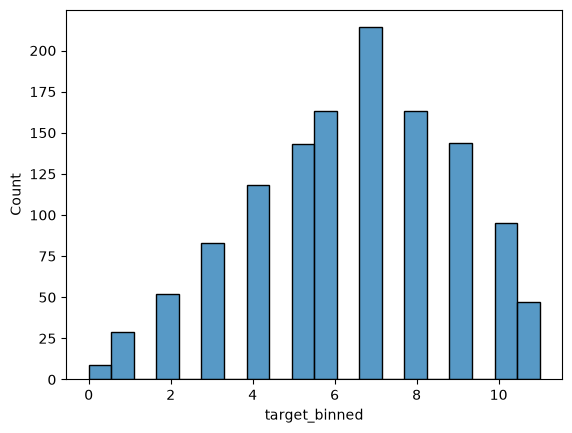

In [3]:
# Create 12 bins of price. 
target = "Price"
df['target_binned'] = pd.cut(df[target], bins=12, labels=False)

# That looks like so.
sns.histplot(df, x="target_binned")

<Axes: xlabel='Weight', ylabel='Ppi'>

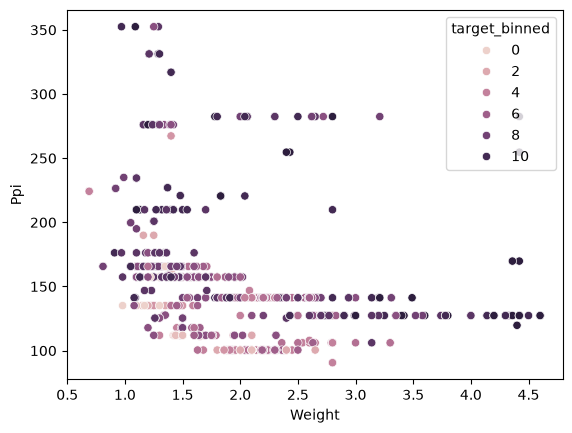

In [4]:
# Now let's take a particularly nasty overlap. Here.
sns.scatterplot(df, x="Weight", y="Ppi", hue="target_binned")

# In real life, does this overlap seem feasible? Probably.
# There's always some overlap (laptops with different specs can cost the same).

# But say this didn't reflect reality and there's some reason to 
# fix the overlap (to which there are many)...

#### ClusterCentroids

In [5]:
from imblearn.under_sampling import ClusterCentroids

# X y split to prevent data leakage
X = df.drop(columns="target_binned", axis=1)
y = df["target_binned"]

strategy = {
    0 : 9,
    1 : 29,
    2 : 52,
    3 : 83,
    4 : 100,
    5 : 100,
    6 : 120,
    7 : 150,
    8 : 130,
    9 : 120,
    10 : 95,
    11 : 47
}


cc = ClusterCentroids(
    sampling_strategy=strategy,
    random_state=321
)

X_resampled, y_resampled = cc.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_resampled = X_resampled.copy()

# Add y back into the X rows
df_resampled["target_binned"] = y_resampled
df_resampled

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows,target_binned
0,2,1.30,9.134616,0,0,135.094211,0,32,1,0,...,0,0,1,0,1,0,0,1,0,0
1,2,0.98,9.232535,0,0,135.094211,0,0,0,0,...,0,0,1,0,1,0,0,0,1,0
2,2,1.45,9.326471,0,0,111.935204,0,0,0,0,...,0,0,1,0,1,0,0,0,1,0
3,4,1.22,9.288274,0,0,157.350512,0,0,0,0,...,0,0,1,0,1,0,0,0,1,0
4,2,2.19,9.268866,0,0,100.454670,0,16,1,0,...,0,0,1,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1030,16,3.49,11.917834,0,0,141.211998,1000,256,0,0,...,0,1,0,0,0,1,0,0,1,11
1031,16,4.36,11.801613,0,1,127.335675,1000,128,0,0,...,0,1,0,0,0,1,0,0,1,11
1032,16,1.83,11.933438,0,1,220.534624,0,512,0,1,...,0,1,0,1,0,0,1,0,0,11
1033,16,4.14,11.887252,0,0,127.335675,1000,512,0,0,...,0,1,0,0,0,1,0,0,1,11


Text(0.5, 1.0, 'Original Data')

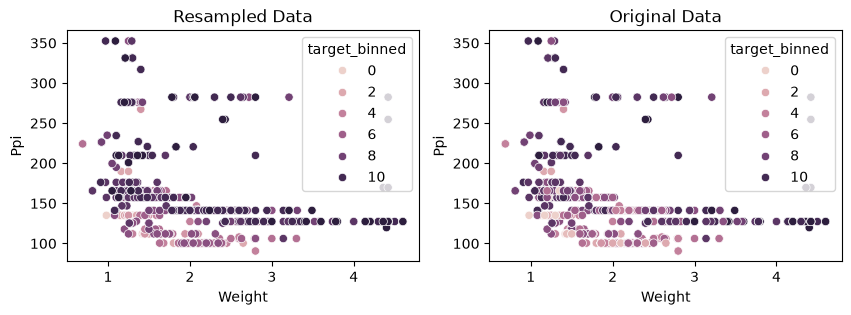

In [ ]:
# Let's look at it again. How did it perform?
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.scatterplot(df, x="Weight", y="Ppi", hue="target_binned", ax=axes[1])    
sns.scatterplot(df_resampled, x="Weight", y="Ppi", hue="target_binned", ax=axes[0])
axes[0].set_title("Resampled Data")
axes[1].set_title("Original Data")
# The resampled data looks almost the same as the original. It is a little less crowded

In [7]:
# But let's do a sanity check. How many rows did it get rid of?
print(df.shape)
print(df_resampled.shape)

(1260, 45)
(1035, 45)
